# Прогнозирование текучести кадров методами машинного обучения
**Воспроизводимое исследование к статье** «Машинное обучение в прогнозировании текучести кадров в управлении человеческим капиталом организации» (Финатлон Форум, секция 29).

Ноутбук повторяет анализ из раздела «Результаты» статьи: подготовка данных и разведочный анализ → сравнение пяти моделей (логистическая регрессия, случайный лес, градиентный бустинг scikit-learn, XGBoost, LightGBM) → факторы оттока (перестановочная важность) → проверка без защищённых признаков → экономическая оценка программы удержания.

**Данные:** IBM HR Analytics Employee Attrition & Performance (1470 сотрудников, 35 признаков). Набор вымышленный, подготовлен специалистами IBM; используется копия из репозитория IBM (`IBM/employee-attrition-aif360`).

**Запуск:** `pip install pandas numpy scipy scikit-learn xgboost lightgbm matplotlib`, затем «Run All». Случайные процессы зафиксированы (`SEED = 42`).

## 0. Настройки и данные

In [8]:
import warnings, os, urllib.request
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import sklearn, xgboost, lightgbm
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict, RepeatedStratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

SEED = 42
DATA_FILE = "emp_attrition.csv"
DATA_URL = "https://raw.githubusercontent.com/IBM/employee-attrition-aif360/master/data/emp_attrition.csv"
FIG_DIR = "figures"; os.makedirs(FIG_DIR, exist_ok=True)
plt.rcParams.update({"font.family": ["Liberation Serif", "Times New Roman", "DejaVu Serif"], "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
from packaging.version import Version
assert Version(xgboost.__version__) >= Version("2.1.4"), (
    "xgboost < 2.1.4 несовместим с scikit-learn >= 1.6: оценки XGBoost в CV молча превращаются в NaN. "
    "Обновите: pip install -U xgboost")
print(dict(sklearn=sklearn.__version__, xgboost=xgboost.__version__, lightgbm=lightgbm.__version__, pandas=pd.__version__, numpy=np.__version__))

if not os.path.exists(DATA_FILE):
    urllib.request.urlretrieve(DATA_URL, DATA_FILE)      # при отсутствии локальной копии
raw = pd.read_csv(DATA_FILE, encoding="utf-8-sig")
print(raw.shape, "| пропусков:", int(raw.isna().sum().sum()))
print(raw.Attrition.value_counts().to_dict(), "| доля увольнений: %.3f" % (raw.Attrition == "Yes").mean())

{'sklearn': '1.9.0', 'xgboost': '3.4.1', 'lightgbm': '4.7.0', 'pandas': '3.0.3', 'numpy': '2.5.4'}
(1470, 35) | пропусков: 0
{'No': 1233, 'Yes': 237} | доля увольнений: 0.161


In [9]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "4"

## 1. Первичный анализ и подготовка признаков

In [10]:
raw

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1465,36,No,Travel_Frequently,884,Research & Development,23,2,Medical,1,2061,...,3,80,1,17,3,3,5,2,0,3
1466,39,No,Travel_Rarely,613,Research & Development,6,1,Medical,1,2062,...,1,80,1,9,5,3,7,7,1,7
1467,27,No,Travel_Rarely,155,Research & Development,4,3,Life Sciences,1,2064,...,2,80,1,6,0,3,6,2,0,3
1468,49,No,Travel_Frequently,1023,Sales,2,3,Medical,1,2065,...,4,80,0,17,3,2,9,6,0,8


In [11]:
raw.info

<bound method DataFrame.info of       Age Attrition     BusinessTravel  DailyRate              Department  \
0      41       Yes      Travel_Rarely       1102                   Sales   
1      49        No  Travel_Frequently        279  Research & Development   
2      37       Yes      Travel_Rarely       1373  Research & Development   
3      33        No  Travel_Frequently       1392  Research & Development   
4      27        No      Travel_Rarely        591  Research & Development   
...   ...       ...                ...        ...                     ...   
1465   36        No  Travel_Frequently        884  Research & Development   
1466   39        No      Travel_Rarely        613  Research & Development   
1467   27        No      Travel_Rarely        155  Research & Development   
1468   49        No  Travel_Frequently       1023                   Sales   
1469   34        No      Travel_Rarely        628  Research & Development   

      DistanceFromHome  Education Education

Удаляются константные признаки (`EmployeeCount`, `StandardHours`, `Over18`) и идентификатор `EmployeeNumber`. Остаётся 30 признаков: 23 числовых/порядковых и 7 категориальных. Порядковые шкалы (удовлетворённость 1–4 и т. п.) трактуются как числовые.

In [12]:
df = raw.drop(columns=["EmployeeCount", "EmployeeNumber", "Over18", "StandardHours"])
y = (df.Attrition == "Yes").astype(int)
X = df.drop(columns="Attrition")
cat = X.select_dtypes("object").columns.tolist()
num = [c for c in X.columns if c not in cat]
print("признаков:", X.shape[1], "| числовых:", len(num), "| категориальных:", len(cat), cat)

d = X.assign(y=y)
print("\nДоля уволившихся по переработкам:\n", d.groupby("OverTime").y.agg(["mean", "count"]).round(3))
print("\nДоля уволившихся по должностям:\n", d.groupby("JobRole").y.agg(["mean", "count"]).round(3).sort_values("mean", ascending=False))
print("\nМедианный месячный доход (0 – остался, 1 – уволился):", d.groupby("y").MonthlyIncome.median().to_dict())

признаков: 30 | числовых: 23 | категориальных: 7 ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Доля уволившихся по переработкам:
            mean  count
OverTime              
No        0.104   1054
Yes       0.305    416

Доля уволившихся по должностям:
                             mean  count
JobRole                                
Sales Representative       0.398     83
Laboratory Technician      0.239    259
Human Resources            0.231     52
Sales Executive            0.175    326
Research Scientist         0.161    292
Healthcare Representative  0.069    131
Manufacturing Director     0.069    145
Manager                    0.049    102
Research Director          0.025     80

Медианный месячный доход (0 – остался, 1 – уволился): {0: 5204.0, 1: 3202.0}


## 1a. Разведочный анализ (табл. 1 и рис. 1 статьи)
Сравнение ушедших и оставшихся сотрудников: медианы [средние], критерий Манна–Уитни; для доли работающих сверхурочно – χ².

In [13]:
from scipy.stats import mannwhitneyu, chi2_contingency
L, S = d[d.y == 1], d[d.y == 0]
spec = [("Age", "Возраст, лет"), ("MonthlyIncome", "Месячный доход, у. е."), ("TotalWorkingYears", "Общий трудовой стаж, лет"),
        ("YearsAtCompany", "Стаж в компании, лет"), ("JobSatisfaction", "Удовлетворённость работой (1–4)"),
        ("EnvironmentSatisfaction", "Удовлетворённость условиями труда (1–4)")]
rows = [{"Показатель": n, "Остались: медиана [среднее]": "%g [%.2f]" % (S[c].median(), S[c].mean()),
         "Ушли: медиана [среднее]": "%g [%.2f]" % (L[c].median(), L[c].mean()), "p (Манн–Уитни)": "%.1e" % mannwhitneyu(L[c], S[c]).pvalue} for c, n in spec]
ot_s, ot_l = (S.OverTime == "Yes").mean(), (L.OverTime == "Yes").mean()
rows.append({"Показатель": "Доля работающих сверхурочно, %", "Остались: медиана [среднее]": "%.1f" % (ot_s * 100),
             "Ушли: медиана [среднее]": "%.1f" % (ot_l * 100), "p (Манн–Уитни)": "%.1e (χ²)" % chi2_contingency(pd.crosstab(d.OverTime, d.y))[1]})
display(pd.DataFrame(rows))

,Показатель,Остались: медиана [среднее],Ушли: медиана [среднее],p (Манн–Уитни)
0,"Возраст, лет",36 [37.56],32 [33.61],5.3e-11
1,"Месячный доход, у. е.",5204 [6832.74],3202 [4787.09],3.0e-14
2,"Общий трудовой стаж, лет",10 [11.86],7 [8.24],2.4e-14
3,"Стаж в компании, лет",6 [7.37],3 [5.13],2.9e-13
4,Удовлетворённость работой (1–4),3 [2.78],3 [2.47],8.0e-05
5,Удовлетворённость условиями труда (1–4),3 [2.77],3 [2.46],2.2e-04
6,"Доля работающих сверхурочно, %",23.4,53.6,8.2e-21 (χ²)


### Рис. 1. Распределения у оставшихся и ушедших

findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Fo

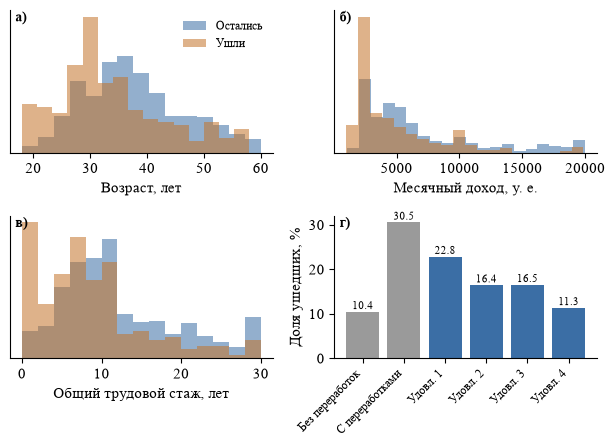

In [14]:
fig, ax = plt.subplots(2, 2, figsize=(6.3, 4.6))
def hist(a, col, xl, bins, clip=None):
    d1, d0 = S[col], L[col]
    if clip: d1, d0 = d1.clip(upper=clip), d0.clip(upper=clip)
    a.hist(d1, bins=bins, density=True, alpha=.55, color="#3b6ea5", label="Остались")
    a.hist(d0, bins=bins, density=True, alpha=.55, color="#c4742a", label="Ушли"); a.set_xlabel(xl); a.set_yticks([])
hist(ax[0, 0], "Age", "Возраст, лет", 15); ax[0, 0].legend(frameon=False, fontsize=8.5)
hist(ax[0, 1], "MonthlyIncome", "Месячный доход, у. е.", 20)
hist(ax[1, 0], "TotalWorkingYears", "Общий трудовой стаж, лет", 15, clip=30)
labs = ["Без переработок", "С переработками", "Удовл. 1", "Удовл. 2", "Удовл. 3", "Удовл. 4"]
vals = [d[d.OverTime == "No"].y.mean(), d[d.OverTime == "Yes"].y.mean()] + [d[d.JobSatisfaction == k].y.mean() for k in (1, 2, 3, 4)]
ax[1, 1].bar(range(6), np.array(vals) * 100, color=["#9a9a9a"] * 2 + ["#3b6ea5"] * 4)
ax[1, 1].set_xticks(range(6)); ax[1, 1].set_xticklabels(labs, rotation=45, ha="right", fontsize=8.5); ax[1, 1].set_ylabel("Доля ушедших, %")
for i, v in enumerate(vals): ax[1, 1].text(i, v * 100 + 0.6, "%.1f" % (v * 100), ha="center", fontsize=8)
for a, t in zip(ax.flat, "абвг"): a.text(0.02, 0.92, t + ")", transform=a.transAxes, fontsize=10, fontweight="bold")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig1_eda.jpg", dpi=600, pil_kwargs={"quality": 92}); plt.show()

## 2. Разбиение и модели
- Стратифицированное разбиение 80/20, `random_state=42`.
- Дисбаланс классов (16,1 %) учитывается **весами классов** (`class_weight="balanced"`, `scale_pos_weight`, веса наблюдений для градиентного бустинга scikit-learn), а не генерацией синтетических наблюдений – так в валидацию не попадают искусственные объекты.
- One-hot для категорий; стандартизация только для логистической регрессии.
- Гиперпараметры: решётка + 5-кратная стратифицированная кросс-валидация **только на обучающей части**, метрика – ROC-AUC.

In [15]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
spw = (ytr == 0).sum() / (ytr == 1).sum()
print("train/test:", len(Xtr), len(Xte), "| уволившихся в тесте:", int(yte.sum()), "| scale_pos_weight = %.2f" % spw)

class BalancedGB(GradientBoostingClassifier):
    """Классический градиентный бустинг scikit-learn с балансировкой классов через веса наблюдений."""
    def fit(self, X, y, sample_weight=None):
        return super().fit(X, y, sample_weight=compute_sample_weight("balanced", y))

def prep(scale):
    return ColumnTransformer([("n", StandardScaler() if scale else "passthrough", num),
                              ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])

models = {
 "LR":   (Pipeline([("p", prep(True)),  ("m", LogisticRegression(class_weight="balanced", max_iter=5000, solver="liblinear", random_state=SEED))]),
          {"m__C": [0.01, 0.03, 0.1, 0.3, 1], "m__penalty": ["l1", "l2"]}),
 "RF":   (Pipeline([("p", prep(False)), ("m", RandomForestClassifier(class_weight="balanced_subsample", n_estimators=400, random_state=SEED, n_jobs=-1))]),
          {"m__max_depth": [4, 6, 10], "m__min_samples_leaf": [3, 5, 10], "m__max_features": ["sqrt", 0.3]}),
 "GB":   (Pipeline([("p", prep(False)), ("m", BalancedGB(n_estimators=200, random_state=SEED))]),
          {"m__max_depth": [2, 3], "m__learning_rate": [0.03, 0.1], "m__subsample": [0.8], "m__min_samples_leaf": [5, 20]}),
 "XGB":  (Pipeline([("p", prep(False)), ("m", XGBClassifier(scale_pos_weight=spw, n_estimators=300, eval_metric="logloss", random_state=SEED, n_jobs=4, verbosity=0))]),
          {"m__max_depth": [2, 3, 4], "m__learning_rate": [0.02, 0.05], "m__subsample": [0.8], "m__colsample_bytree": [0.6, 0.8], "m__min_child_weight": [1, 5]}),
 "LGBM": (Pipeline([("p", prep(False)), ("m", LGBMClassifier(class_weight="balanced", n_estimators=300, random_state=SEED, n_jobs=4, verbose=-1))]),
          {"m__num_leaves": [4, 8, 16], "m__learning_rate": [0.02, 0.05], "m__colsample_bytree": [0.6, 0.8], "m__min_child_samples": [10, 20, 40]}),
}
NAMES = {"LR": "Логистическая регрессия", "RF": "Случайный лес", "GB": "Градиентный бустинг", "XGB": "XGBoost", "LGBM": "LightGBM"}
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
fitted, res, roc, proba = {}, {}, {}, {}
for k, (pipe, grid) in models.items():
    gs = GridSearchCV(pipe, grid, scoring="roc_auc", cv=cv, n_jobs=1, refit=True, error_score="raise").fit(Xtr, ytr)
    best_est = gs.best_estimator_
    p = best_est.predict_proba(Xte)[:, 1]; pred = (p >= 0.5).astype(int)
    sc = cross_val_score(best_est, Xtr, ytr, scoring="roc_auc", cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED), error_score="raise")
    res[k] = dict(params=gs.best_params_, cv_auc=sc.mean(), cv_sd=sc.std(), auc=roc_auc_score(yte, p),
                  acc=accuracy_score(yte, pred), prec=precision_score(yte, pred), rec=recall_score(yte, pred), f1=f1_score(yte, pred))
    fitted[k], proba[k], roc[k] = best_est, p, roc_curve(yte, p)
    print(k, "готово | лучшие параметры:", gs.best_params_)

best = max(res, key=lambda k: res[k]["cv_auc"])                       # лучшая модель выбирается по CV на обучающей части
boost = max(["GB", "XGB", "LGBM"], key=lambda k: res[k]["cv_auc"])    # лучший из бустингов – для сравнения важностей
print("Лучшая модель по CV:", NAMES[best], "| лучший бустинг:", NAMES[boost])

train/test: 1176 294 | уволившихся в тесте: 47 | scale_pos_weight = 5.19
LR готово | лучшие параметры: {'m__C': 0.1, 'm__penalty': 'l2'}
RF готово | лучшие параметры: {'m__max_depth': 10, 'm__max_features': 'sqrt', 'm__min_samples_leaf': 3}
GB готово | лучшие параметры: {'m__learning_rate': 0.1, 'm__max_depth': 2, 'm__min_samples_leaf': 5, 'm__subsample': 0.8}
XGB готово | лучшие параметры: {'m__colsample_bytree': 0.8, 'm__learning_rate': 0.05, 'm__max_depth': 2, 'm__min_child_weight': 5, 'm__subsample': 0.8}
LGBM готово | лучшие параметры: {'m__colsample_bytree': 0.6, 'm__learning_rate': 0.05, 'm__min_child_samples': 40, 'm__num_leaves': 16}
Лучшая модель по CV: Логистическая регрессия | лучший бустинг: XGBoost


## 3. Таблица 2: качество моделей
95 % доверительные интервалы AUC на тесте – бутстрэп (2000 повторов). На тесте всего 47 уволившихся, поэтому интервалы широкие (≈ 0,15) и строгое ранжирование моделей статистически не обосновано.

In [16]:
rng = np.random.default_rng(SEED)
yt = yte.values
def boot_ci(p, n=2000):
    a = []
    for _ in range(n):
        i = rng.integers(0, len(yt), len(yt))
        if yt[i].sum() in (0, len(yt)): continue
        a.append(roc_auc_score(yt[i], p[i]))
    return np.percentile(a, [2.5, 97.5])
ci = {k: boot_ci(proba[k]) for k in fitted}
t1 = pd.DataFrame({
    "Модель": [NAMES[k] for k in res],
    "AUC на тесте": [res[k]["auc"] for k in res],
    "95% ДИ": ["%.3f–%.3f" % tuple(ci[k]) for k in res],
    "AUC в CV 5×3": ["%.3f ± %.3f" % (res[k]["cv_auc"], res[k]["cv_sd"]) for k in res],
    "Accuracy": [res[k]["acc"] for k in res], "Precision": [res[k]["prec"] for k in res],
    "Recall": [res[k]["rec"] for k in res], "F1": [res[k]["f1"] for k in res]}).round(3)
display(t1)
print("Accuracy тривиального прогноза «никто не уйдёт» на тесте: %.3f" % (1 - yte.mean()))

,Модель,AUC на тесте,95% ДИ,AUC в CV 5×3,Accuracy,Precision,Recall,F1
0,Логистическая регрессия,0.812,0.735–0.882,0.829 ± 0.031,0.769,0.376,0.681,0.485
1,Случайный лес,0.791,0.713–0.860,0.800 ± 0.033,0.830,0.440,0.234,0.306
2,Градиентный бустинг,0.797,0.715–0.872,0.806 ± 0.027,0.810,0.433,0.617,0.509
3,XGBoost,0.797,0.714–0.870,0.813 ± 0.027,0.786,0.386,0.574,0.462
4,LightGBM,0.774,0.689–0.847,0.810 ± 0.036,0.830,0.457,0.340,0.390


Accuracy тривиального прогноза «никто не уйдёт» на тесте: 0.840


### Рис. 2. ROC-кривые на тестовой выборке

findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Fo

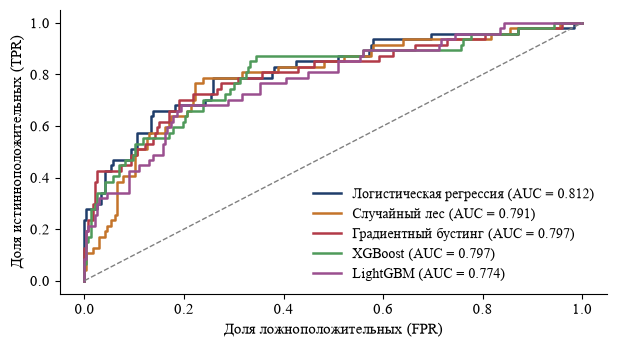

In [17]:
col = {"LR": "#1f3d6b", "RF": "#c4742a", "GB": "#b23a48", "XGB": "#4f9a5a", "LGBM": "#9a4f8f"}
fig, ax = plt.subplots(figsize=(6.3, 3.6))
for k, (fpr, tpr, _) in roc.items():
    ax.plot(fpr, tpr, color=col[k], lw=1.8, label="%s (AUC = %.3f)" % (NAMES[k], res[k]["auc"]))
ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
ax.set_xlabel("Доля ложноположительных (FPR)"); ax.set_ylabel("Доля истинноположительных (TPR)")
ax.legend(loc="lower right", frameon=False, fontsize=10)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig2_roc.jpg", dpi=600, pil_kwargs={"quality": 92}); plt.show()

## 4. Out-of-fold прогнозы и проверка без защищённых признаков
OOF прогнозы нужны для экономической оценки: каждый из 1470 сотрудников оценивается моделью, которая его не видела. Дополнительно проверяется, насколько падает качество, если убрать возраст, пол и семейное положение.

In [18]:
bm = fitted[best]
oof = cross_val_predict(clone(bm), X, y, cv=cv, method="predict_proba")[:, 1]
oof_auc = roc_auc_score(y, oof)

prot = ["Age", "Gender", "MaritalStatus"]
num2 = [c for c in num if c not in prot]; cat2 = [c for c in cat if c not in prot]
bm2 = clone(bm).set_params(p=ColumnTransformer([("n", StandardScaler() if best == "LR" else "passthrough", num2),
                                                ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat2)]))
bm2.fit(Xtr.drop(columns=prot), ytr)
auc_np_test = roc_auc_score(yte, bm2.predict_proba(Xte.drop(columns=prot))[:, 1])
oof_np = cross_val_predict(bm2, X.drop(columns=prot), y, cv=cv, method="predict_proba")[:, 1]
auc_np_oof = roc_auc_score(y, oof_np)
print("OOF AUC, все признаки: %.4f | без защищённых: %.4f | разница: %.4f" % (oof_auc, auc_np_oof, oof_auc - auc_np_oof))
print("AUC на тесте, все признаки: %.3f | без защищённых: %.3f" % (res[best]["auc"], auc_np_test))

OOF AUC, все признаки: 0.8272 | без защищённых: 0.8205 | разница: 0.0067
AUC на тесте, все признаки: 0.812 | без защищённых: 0.796


## 5. Факторы оттока
Для каждого исходного признака значения случайно перемешиваются в отложенной части кросс-валидации, и измеряется снижение ROC-AUC; 5 фолдов × 10 перестановок, модель обучается заново в каждом фолде. Чем сильнее падает качество, тем важнее признак для прогноза. Это метод, не зависящий от типа модели; он показывает вклад признака в прогноз, а не причину увольнения. Направление связи берётся из знака коэффициента логистической регрессии (для категориальных – категория с наибольшим коэффициентом). Устойчивость проверяется сопоставлением с лучшим бустингом (корреляция Спирмена рангов).

In [19]:
def perm_imp(template, n_rep=10):
    r = np.random.default_rng(SEED); drops = {f: [] for f in X.columns}
    for tr, te in cv.split(X, y):
        m = clone(template).fit(X.iloc[tr], y.iloc[tr]); Xh, yh = X.iloc[te], y.iloc[te]
        base = roc_auc_score(yh, m.predict_proba(Xh)[:, 1])
        for f in X.columns:
            ds = []
            for _ in range(n_rep):
                Xp = Xh.copy(); Xp[f] = r.permutation(Xp[f].values)
                ds.append(base - roc_auc_score(yh, m.predict_proba(Xp)[:, 1]))
            drops[f].append(np.mean(ds))
    return pd.DataFrame({"mean": {f: np.mean(v) for f, v in drops.items()}, "sd": {f: np.std(v) for f, v in drops.items()}})

pi_b = perm_imp(bm).sort_values("mean", ascending=False)
pi_x = perm_imp(fitted[boost] if boost != best else bm)
rank_x = pi_x["mean"].rank(ascending=False).astype(int)
rho = spearmanr(pi_b["mean"].values, pi_x.loc[pi_b.index, "mean"].values)[0]

lr_full = clone(fitted["LR"]).fit(X, y)
pre = lr_full.named_steps["p"]; co = pd.Series(lr_full.named_steps["m"].coef_[0], index=pre.get_feature_names_out())
def direction(f):
    if f in num: return "растёт с ростом значения" if co["n__" + f] > 0 else "снижается с ростом значения"
    sub = co[[i for i in co.index if i.startswith("c__" + f + "_")]]
    return "выше всего: " + sub.idxmax().split("__", 1)[1][len(f) + 1:]
t2 = pd.DataFrame({"Фактор": pi_b.index[:10], "Снижение AUC": pi_b["mean"].values[:10].round(4), "± по фолдам": pi_b["sd"].values[:10].round(4),
                   "Направление": [direction(f) for f in pi_b.index[:10]],
                   "Ранг в " + NAMES[boost]: [int(rank_x[f]) for f in pi_b.index[:10]]}, index=range(1, 11))
display(t2)
print("Спирмен (важности %s vs %s): %.3f | первый фактор / второй = %.2f" % (NAMES[best], NAMES[boost], rho, pi_b["mean"].iloc[0] / pi_b["mean"].iloc[1]))

,Фактор,Снижение AUC,± по фолдам,Направление,Ранг в XGBoost
1,OverTime,0.0796,0.0112,выше всего: Yes,1
2,YearsWithCurrManager,0.0260,0.0080,снижается с ростом значения,16
3,YearsInCurrentRole,0.0233,0.0099,снижается с ростом значения,20
4,JobSatisfaction,0.0209,0.0032,снижается с ростом значения,4
5,EnvironmentSatisfaction,0.0182,0.0130,снижается с ростом значения,5
6,YearsSinceLastPromotion,0.0181,0.0079,растёт с ростом значения,15
7,NumCompaniesWorked,0.0167,0.0134,растёт с ростом значения,6
8,YearsAtCompany,0.0152,0.0162,растёт с ростом значения,18
9,MaritalStatus,0.0141,0.0046,выше всего: Single,21
10,JobInvolvement,0.0132,0.0039,снижается с ростом значения,13


Спирмен (важности Логистическая регрессия vs XGBoost): 0.551 | первый фактор / второй = 3.07


### Рис. 3. Снижение ROC-AUC при перестановке признака (топ-10)

findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Fo

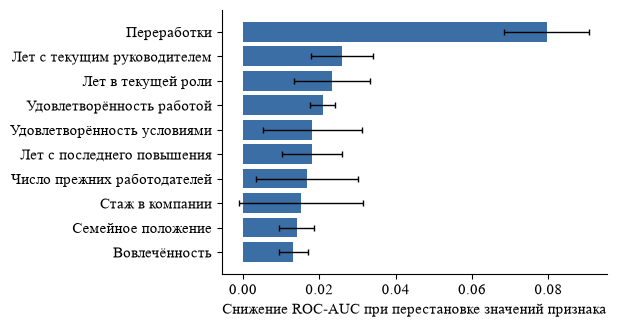

In [20]:
lab = {"OverTime": "Переработки", "YearsSinceLastPromotion": "Лет с последнего повышения", "NumCompaniesWorked": "Число прежних работодателей",
       "EnvironmentSatisfaction": "Удовлетворённость условиями", "YearsWithCurrManager": "Лет с текущим руководителем",
       "TotalWorkingYears": "Общий трудовой стаж", "JobSatisfaction": "Удовлетворённость работой", "JobRole": "Должность",
       "Department": "Подразделение", "MaritalStatus": "Семейное положение", "BusinessTravel": "Командировки",
       "DistanceFromHome": "Расстояние до работы", "Age": "Возраст", "MonthlyIncome": "Ежемесячный доход",
       "StockOptionLevel": "Уровень опционов", "JobInvolvement": "Вовлечённость", "JobLevel": "Уровень должности",
       "WorkLifeBalance": "Баланс работы и жизни", "YearsAtCompany": "Стаж в компании", "YearsInCurrentRole": "Лет в текущей роли"}
top = pi_b.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(6.3, 3.4))
ax.barh([lab.get(i, i) for i in top.index], top["mean"].values, xerr=top["sd"].values, color="#3b6ea5", error_kw=dict(lw=1, capsize=2))
ax.set_xlabel("Снижение ROC-AUC при перестановке значений признака"); ax.spines["left"].set_visible(True)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig3_perm.jpg", dpi=600, pil_kwargs={"quality": 92}); plt.show()

## 6. Экономическая оценка программы удержания
Для сотрудника *i*: оклад $S_i = 12 \times$ `MonthlyIncome`, $y_i = 1$ для уволившегося. Программа охватывает множество $A$ сотрудников с наивысшим OOF-риском.

$$C = c\sum_{i\in A} S_i,\qquad B = e\,r\sum_{i\in A} y_i S_i,\qquad ROI=\frac{B-C}{C},\qquad e^{*}=\frac{c\sum_{i\in A}S_i}{r\sum_{i\in A}y_iS_i}$$

где $c$ – затраты на участника (доля оклада), $r$ – издержки замены (доля оклада), $e$ – доля потенциально уволившихся, удержанных программой. Значения $c$ и $e$ – допущения автора, не эмпирические оценки; $r$ в консервативном сценарии ≈ медиане 21 % (Boushey & Glynn, 2012). Выгода считается по фактическим исходам (ретроспективная оценка на модельных данных). Деньги – в условных единицах данных.

In [21]:
sal = (X.MonthlyIncome * 12).values; leave = y.values; N = len(y)
order = np.argsort(-oof)
c = 0.05
scen = {"Консервативный": (0.20, 0.20), "Базовый": (0.50, 0.30), "Оптимистичный": (1.00, 0.40)}

def econ(idx, r, e, c=c):
    tp = leave[idx] == 1
    cost = (c * sal[idx]).sum(); ben = (e * r * sal[idx][tp]).sum()
    return dict(n=len(idx), recall=tp.sum() / leave.sum(), prec=tp.mean(), cost=cost, ben=ben, net=ben - cost, roi=(ben - cost) / cost)

rows = []
for sname, (r, e) in scen.items():
    for label, idx in [("Модель, 10 % риска", order[:round(0.10 * N)]), ("Модель, 20 % риска", order[:round(0.20 * N)]),
                       ("Все сотрудники", np.arange(N))]:
        v = econ(idx, r, e)
        rows.append({"Сценарий": sname, "Стратегия": label, "Охват": v["n"], "Доля ушедших в охвате, %": round(v["recall"] * 100, 1),
                     "Затраты, тыс.": round(v["cost"] / 1e3), "Выгода, тыс.": round(v["ben"] / 1e3),
                     "Чистый эффект, тыс.": round(v["net"] / 1e3), "ROI, %": round(v["roi"] * 100)})
t3 = pd.DataFrame(rows); display(t3)

print("Точность и охват среди топ-k по риску:")
for s in (0.05, 0.10, 0.20, 0.30):
    idx = order[:round(s * N)]; p = leave[idx].mean()
    print("  топ-%2d%%: доля уволившихся %.3f, кратность %.2f, охват уволившихся %.3f" % (s * 100, p, p / leave.mean(), leave[idx].sum() / leave.sum()))

idx20 = order[:round(0.2 * N)]
be = {r: round(c * sal[idx20].sum() / (r * sal[idx20][leave[idx20] == 1].sum()), 3) for r in (0.2, 0.5, 1.0)}
print("\nБезубыточная эффективность e* при охвате 20 %:", be)

shares = np.arange(0.02, 1.001, 0.01)
for sname, (r, e) in scen.items():
    nets = [econ(order[:round(s * N)], r, e)["net"] for s in shares]
    print("  максимум чистого эффекта, %-15s: охват %.0f %%, %.0f тыс." % (sname, shares[int(np.argmax(nets))] * 100, max(nets) / 1e3))

,Сценарий,Стратегия,Охват,"Доля ушедших в охвате, %","Затраты, тыс.","Выгода, тыс.","Чистый эффект, тыс.","ROI, %"
0,Консервативный,"Модель, 10 % риска",147,43.0,406,203,-203,-50
1,Консервативный,"Модель, 20 % риска",294,59.5,799,270,-529,-66
2,Консервативный,Все сотрудники,1470,100.0,5736,545,-5191,-91
3,Базовый,"Модель, 10 % риска",147,43.0,406,760,354,87
4,Базовый,"Модель, 20 % риска",294,59.5,799,1012,213,27
5,Базовый,Все сотрудники,1470,100.0,5736,2042,-3693,-64
6,Оптимистичный,"Модель, 10 % риска",147,43.0,406,2026,1620,399
7,Оптимистичный,"Модель, 20 % риска",294,59.5,799,2698,1899,238
8,Оптимистичный,Все сотрудники,1470,100.0,5736,5446,-290,-5


Точность и охват среди топ-k по риску:
  топ- 5%: доля уволившихся 0.811, кратность 5.03, охват уволившихся 0.253
  топ-10%: доля уволившихся 0.694, кратность 4.30, охват уволившихся 0.430
  топ-20%: доля уволившихся 0.480, кратность 2.97, охват уволившихся 0.595
  топ-30%: доля уволившихся 0.385, кратность 2.39, охват уволившихся 0.717

Безубыточная эффективность e* при охвате 20 %: {0.2: np.float64(0.592), 0.5: np.float64(0.237), 1.0: np.float64(0.118)}
  максимум чистого эффекта, Консервативный : охват 2 %, -22 тыс.
  максимум чистого эффекта, Базовый        : охват 9 %, 371 тыс.
  максимум чистого эффекта, Оптимистичный  : охват 28 %, 2093 тыс.


### Рис. 4. Условный ROI в зависимости от доли охвата

findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Font family 'Liberation Serif' not found.
findfont: Fo

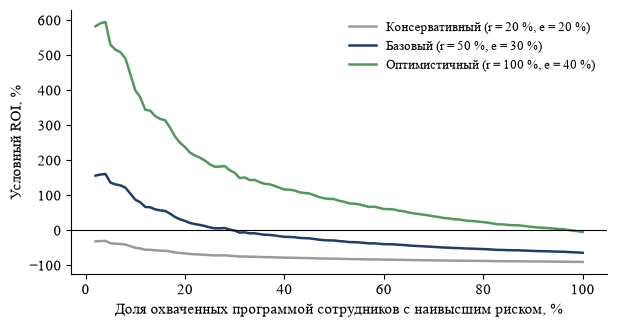

In [22]:
fig, ax = plt.subplots(figsize=(6.3, 3.4))
for (sname, (r, e)), cl in zip(scen.items(), ["#9a9a9a", "#1f3d6b", "#4f9a5a"]):
    ax.plot(shares * 100, [econ(order[:round(s * N)], r, e)["roi"] * 100 for s in shares], color=cl, lw=1.8,
            label="%s (r = %d %%, e = %d %%)" % (sname, r * 100, e * 100))
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Доля охваченных программой сотрудников с наивысшим риском, %"); ax.set_ylabel("Условный ROI, %")
ax.legend(frameon=False, fontsize=9.5)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/fig4_roi.jpg", dpi=600, pil_kwargs={"quality": 92}); plt.show()